# Test Code Execution with Power Profiling

In [1]:
# Import modules
import lassi.code_manager
import lassi.llm_methods
from lassi.get_power import report_gpu_memory
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.code_manager
%aimport lassi.llm_methods
%aimport lassi.get_power
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary

prompts = PromptDictionary()

In [2]:
report_gpu_memory()


----- GPU Memory Status:
 GPU 0: 435 MiB used, 15940 MiB free, 16376 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 3.11 W, P8



In [3]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Tue_May_27_02:21:03_PDT_2025
Cuda compilation tools, release 12.9, V12.9.86
Build cuda_12.9.r12.9/compiler.36037853_0


In [4]:
!nvidia-smi -q


==============NVSMI LOG==============

Timestamp                                 : Sat Nov  8 13:36:52 2025
Driver Version                            : 570.195.03
CUDA Version                              : 12.8

Attached GPUs                             : 1
GPU 00000000:01:00.0
    Product Name                          : NVIDIA RTX 5000 Ada Generation Laptop GPU
    Product Brand                         : NVIDIA RTX
    Product Architecture                  : Ada Lovelace
    Display Mode                          : Disabled
    Display Active                        : Disabled
    Persistence Mode                      : Disabled
    Addressing Mode                       : N/A
    MIG Mode
        Current                           : N/A
        Pending                           : N/A
    Accounting Mode                       : Disabled
    Accounting Mode Buffer Size           : 4000
    Driver Model
        Current                           : N/A
        Pending                       

In [5]:
!nvidia-smi --query-gpu=pci.bus_id,pci.device_id,pci.domain,pci.bus --format=csv

pci.bus_id, pci.device_id, pci.domain, pci.bus
00000000:01:00.0, 0x273010DE, 0x0000, 0x01


In [7]:
# Code to test
folder = "test_codes/dense-embedding/"
code_filename = "dense-embedding-cuda_main.cu"
exe_input_parameters = ["100000", "128", "100", "--dump"]

with open(folder + "/" + code_filename, 'r') as file:
    refactored_code = file.read()
file.close()

# Parameters
power_measure = True

source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_89 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100

In [8]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_89', '-O3', 'test_codes/dense-embedding//dense-embedding-cuda_main.cu', '-o', 'test_codes/dense-embedding//dense-embedding-cuda_main']

Compilation of code successful!



In [9]:
execute_result, exe_output, total_energy_joules, ave_power, std_power, duration, metrics_results_string = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

TypeError: execute_code() missing 6 required positional arguments: 'exe_input_parameters', 'power_measure', 'code_source', 'target_lang', 'build_script', and 'make_script'

In [ ]:
# Measure system idle power
"""
print("Measure system idle power...")
idle_energy_joules, idle_ave_power = lassi.get_power.idlepower(duration)
actual_energy = total_energy_joules - idle_energy_joules
actual_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nActual measured values during runtime for " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{actual_ave_power:.2f} W" + color.END)
print("Total Energy During Exe Runtime: " + color.BOLD + f"{actual_energy:.2f} J" + color.END)
"""

# Code Validation with LLM-as-a-Judge

In [5]:
# Run source code
# Call llm-as-a-judge method
# Source Code to test
folder = "test_codes/jacobi/"
code_filename = "main.cu"
with open(folder + "/" + code_filename, 'r') as file:
    source_code = file.read()
file.close()

In [6]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main.cu', '-o', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main']

Compilation of code successful!



----- >>> System check BEFORE exe code...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.86 W, P0



Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]

Working directory: test_codes/all-pairs-distance
Execute command: ['./all-pairs-distance-cuda_main', '10000']




----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

CPU time: 120559.000000 (us)
Average kernel execution time: 167.371902 (us)
PASS
Average kernel execution time: 175.180099 (us)
PASS
Average kernel execution time: 169.211502 (us)
PASS

----- < END: Standard Output > -----

GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


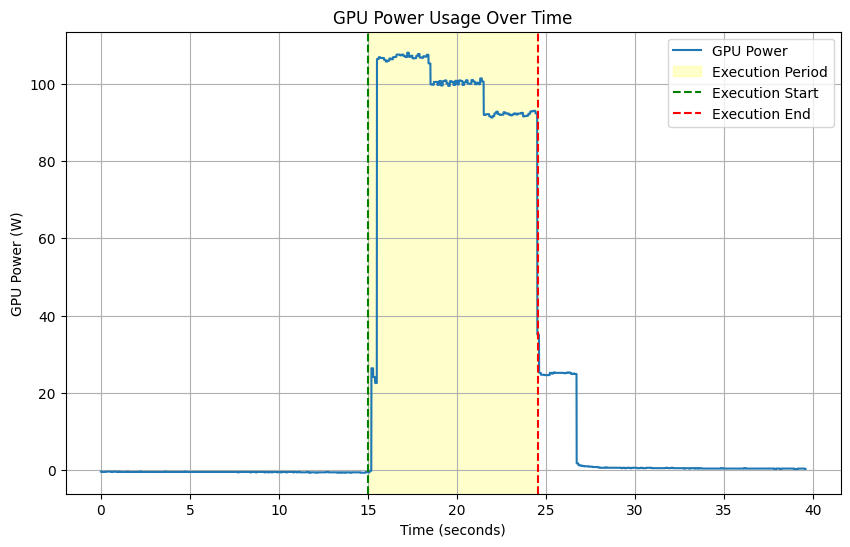

Start time: 15.001 -- End time: 24.58
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000252 kWh
  0.2524 Wh
  908.62 J
Average GPU power: 94.94 W +/- 20.46 
 with sample standard deviation.
Total Energy During Exe Runtime:   908.62 J
Code execution duration:  9.58 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.64 W, P0



In [7]:
execute_result_source, exe_output_source, total_energy_joules_source, ave_power_source, std_power, duration_source, metrics_results_string_source = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Save source code results into a local JSON file for quick loading

In [8]:
llm_source = "argo"
model_judge = "gpto3mini"
num_ctx = 20000
general_system_prompt = prompts.get_system_prompt("general_system_ee")
input_content_llmjudge_dict = {
    "source_code": source_code,
    "source_stdout": exe_output_source,
    "source_metrics": metrics_results_string_source,
    "refactored_code": refactored_code,
    "refactored_stdout": exe_output,
    "refactored_metrics": metrics_results_string,
} 
display_response = True
verifyprompt = False

# Call LLM-as-a-judge to review SOURCE CODE and REFACTORED CODE to evaluate if likely valid
valid_code_flag = lassi.llm_methods.llm_judge(
    llm_source,
    model_judge,
    num_ctx,
    general_system_prompt,
    input_content_llmjudge_dict,
    display_response,
    verifyprompt
)
print(f"\nResult: {valid_code_flag}")



--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----





----- END LLM RESPONSE -----


Result: NONE
